# 2. Modelling Consumer Preference

## b. Linear Absolute disutility

In [78]:
from pathlib import Path

repo = Path.cwd()

print("Current working directory:")
print(repo)

print("\nFiles and folders:")
for item in repo.iterdir():
    print(item.name)

Current working directory:
F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final

Files and folders:
.ipynb_checkpoints
Assignment_01.ipynb
Assignment_01_final.ipynb
data
results
src


In [79]:

from pathlib import Path

# Repository root
repo = Path.cwd()

# Create result folders and their plot subfolders
result_types = [
    "Q2_linear",
    "Q2_quadratic",
    "Q2_temporal"
]

results_dirs = {}
plots_dirs = {}

for result_type in result_types:
    results_dir = repo / "results" / result_type
    plots_dir = results_dir / "plots"

    results_dir.mkdir(parents=True, exist_ok=True)
    plots_dir.mkdir(parents=True, exist_ok=True)

    results_dirs[result_type] = results_dir
    plots_dirs[result_type] = plots_dir

print("Results and plots folders are ready.")

for result_type in result_types:
    print(f"{result_type}: {results_dirs[result_type]}")
    print(f"  Plots: {plots_dirs[result_type]}")


Results and plots folders are ready.
Q2_linear: F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final\results\Q2_linear
  Plots: F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final\results\Q2_linear\plots
Q2_quadratic: F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final\results\Q2_quadratic
  Plots: F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final\results\Q2_quadratic\plots
Q2_temporal: F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final\results\Q2_temporal
  Plots: F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final\results\Q2_temporal\plots


In [80]:
import sys

sys.path.insert(0, str(repo))

from src.data_loader import load_question
from src.model import FlexibleConsumerModel

print("Repository modules imported successfully.")

Repository modules imported successfully.


In [81]:
data = load_question(
    "Q2_linear",
    data_dir=repo / "data"
)

print(data.summary())

Case                 : Q2_linear
Consumer             : C_02_L
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : None
Min daily energy     : None
Reference profile    : yes (32.3 kWh/day)
Disutility lin/quad  : 1.43 / None
Battery              : no
Next-day forecasts   : yes


### Inspect the parameters

In [82]:
print("Reference load:")
print(data.reference_load)

print("\nLinear disutility coefficient:")
print(data.linear_disutility)

print("\nImport tariff:")
print(data.import_tariff)

print("\nExport tariff:")
print(data.export_tariff)

print("\nPV marginal cost:")
print(data.pv_marginal_cost)

print("\nLoad minimum:")
print(data.load_min_kWh)

print("\nLoad maximum:")
print(data.load_max_kWh)

Reference load:
[0.   0.   0.   0.   0.   0.24 0.72 1.5  2.1  2.7  3.6  4.2  4.8  4.68
 3.6  2.4  1.2  0.48 0.12 0.   0.   0.   0.   0.  ]

Linear disutility coefficient:
1.43

Import tariff:
0.5

Export tariff:
0.4

PV marginal cost:
1.41

Load minimum:
0.0

Load maximum:
6.0


### Check effective prices

In [83]:
import numpy as np
import pandas as pd

effective_import_price = (
    data.energy_price
    + data.import_tariff
)

effective_export_price = (
    data.energy_price
    - data.export_tariff
)

price_table = pd.DataFrame({
    "hour": data.hours,
    "market_price": data.energy_price,
    "import_price": effective_import_price,
    "export_price": effective_export_price
})

display(price_table.round(3))

,hour,market_price,import_price,export_price
0,0,1.10,1.60,0.70
1,1,1.05,1.55,0.65
2,2,1.00,1.50,0.60
3,3,0.90,1.40,0.50
4,4,0.85,1.35,0.45
5,5,1.01,1.51,0.61
6,6,1.05,1.55,0.65
7,7,1.20,1.70,0.80
8,8,1.40,1.90,1.00
9,9,1.60,2.10,1.20


In [84]:
print(
    "Minimum effective export price:",
    effective_export_price.min()
)

assert np.all(effective_export_price > 0)

print("All effective export prices are positive.")

Minimum effective export price: 0.44999999999999996
All effective export prices are positive.


### Check Gurobi

In [85]:
import gurobipy as gp

print("Gurobi version:", gp.gurobi.version())

Gurobi version: (13, 0, 1)


In [86]:
from gurobipy import GRB


class LinearDisutilityModel(FlexibleConsumerModel):

    def __init__(self, data, cL=None, name="Q2_linear", verbose=False):

        super().__init__(
            data,
            name=name,
            verbose=verbose
        )

        if cL is None:
            cL = data.linear_disutility

        self.cL = float(cL)

        if self.cL <= 0:
            raise ValueError("cL must be positive.")

        if data.reference_load is None:
            raise ValueError(
                "Reference load is required for Q2(b)."
            )

    def build(self):

        d = self.data
        m = self.m
        T = self.T

        # ----------------------------------------------------
        # Decision variables
        # ----------------------------------------------------

        L = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="load"
        )

        PV = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="pv"
        )

        P_imp = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="import"
        )

        P_exp = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="export"
        )

        x = m.addVars(
            T,
            lb=0,
            vtype=GRB.CONTINUOUS,
            name="deviation"
        )

        # Store variables so the repository can retrieve them
        self.var["load"] = L
        self.var["pv"] = PV
        self.var["import"] = P_imp
        self.var["export"] = P_exp
        self.var["deviation"] = x

        # ----------------------------------------------------
        # Effective prices
        # ----------------------------------------------------

        p_imp = (
            d.energy_price
            + d.import_tariff
        )

        p_exp = (
            d.energy_price
            - d.export_tariff
        )

        # ----------------------------------------------------
        # Objective
        #
        # max sum [
        #   -cL*x
        #   -cPV*PV
        #   -p_imp*P_imp
        #   +p_exp*P_exp
        # ]
        # ----------------------------------------------------

        m.setObjective(
            gp.quicksum(
                -self.cL * x[t]
                - d.pv_marginal_cost * PV[t]
                - p_imp[t] * P_imp[t]
                + p_exp[t] * P_exp[t]
                for t in T
            ),
            GRB.MAXIMIZE
        )

        # ----------------------------------------------------
        # (2b-2) Energy balance
        # ----------------------------------------------------

        self.con["balance"] = m.addConstrs(
            PV[t]
            - L[t]
            - P_exp[t]
            + P_imp[t]
            == 0
            for t in T
        )

        # ----------------------------------------------------
        # (2b-3) Load bounds
        # ----------------------------------------------------

        self.con["load_min"] = m.addConstrs(
            L[t] >= d.load_min_kWh
            for t in T
        )

        self.con["load_max"] = m.addConstrs(
            L[t] <= d.load_max_kWh
            for t in T
        )

        # ----------------------------------------------------
        # (2b-4) PV bounds
        # ----------------------------------------------------

        self.con["pv_min"] = m.addConstrs(
            PV[t] >= 0
            for t in T
        )

        self.con["pv_max"] = m.addConstrs(
            PV[t] <= d.pv_available[t]
            for t in T
        )

        # ----------------------------------------------------
        # (2b-5) Import >= 0
        # ----------------------------------------------------

        self.con["import_min"] = m.addConstrs(
            P_imp[t] >= 0
            for t in T
        )

        # ----------------------------------------------------
        # (2b-6) Export >= 0
        # ----------------------------------------------------

        self.con["export_min"] = m.addConstrs(
            P_exp[t] >= 0
            for t in T
        )

        # ----------------------------------------------------
        # (2b-7)
        #
        # x >= L - L_ref
        # ----------------------------------------------------

        self.con["dev_pos"] = m.addConstrs(
            x[t]
            >= L[t] - d.reference_load[t]
            for t in T
        )

        # ----------------------------------------------------
        # (2b-8)
        #
        # x >= L_ref - L
        # ----------------------------------------------------

        self.con["dev_neg"] = m.addConstrs(
            x[t]
            >= d.reference_load[t] - L[t]
            for t in T
        )

        # ----------------------------------------------------
        # (2b-9)
        #
        # x >= 0
        # ----------------------------------------------------

        self.con["deviation_nonnegative"] = m.addConstrs(
            x[t] >= 0
            for t in T
        )

        m.update()

        return self

In [87]:
model = LinearDisutilityModel(data)

model.build()

results_B = model.solve()

print(results_B)

status: OPTIMAL | objective: -44.31 DKK
daily totals (kWh): load=23.1, pv=26.1, import=0.0, export=3.0


The objective value is -44.31 which means the net cost is 44.31 where the load is 23.1 and the PV generation is 26.1 which leads to export 3 units

In [88]:
display(
    results_B.hourly.round(4)
)

,price,pv_available,reference_load,load,pv,import,export,deviation,dual_balance,dual_load_min,dual_load_max,dual_pv_min,dual_pv_max,dual_import_min,dual_export_min,dual_dev_pos,dual_dev_neg,dual_deviation_nonnegative
hour,,,,,,,,,,,,,,,,,,
0,1.10,0.00,0.00,0.00,0.00,0.0,0.0,0.00,-1.60,-3.03,0.0,0.00,0.19,0.00,-0.90,-1.43,0.00,0.0
1,1.05,0.00,0.00,0.00,0.00,0.0,0.0,0.00,-1.55,-2.98,0.0,0.00,0.14,0.00,-0.90,-1.43,0.00,0.0
2,1.00,0.00,0.00,0.00,0.00,0.0,0.0,0.00,-1.50,-2.93,0.0,0.00,0.09,0.00,-0.90,-1.43,0.00,0.0
3,0.90,0.00,0.00,0.00,0.00,0.0,0.0,0.00,-1.40,-2.83,0.0,-0.01,0.00,0.00,-0.90,-1.43,0.00,0.0
4,0.85,0.00,0.00,0.00,0.00,0.0,0.0,0.00,-1.35,-2.78,0.0,-0.06,0.00,0.00,-0.90,-1.43,0.00,0.0
5,1.01,0.30,0.24,0.24,0.24,0.0,0.0,0.00,-1.41,0.00,0.0,0.00,0.00,-0.10,-0.80,0.00,-1.41,0.0
6,1.05,0.84,0.72,0.72,0.72,0.0,0.0,0.00,-1.41,0.00,0.0,0.00,0.00,-0.14,-0.76,0.00,-1.41,0.0
7,1.20,1.26,1.50,1.26,1.26,0.0,0.0,0.24,-1.43,0.00,0.0,0.00,0.02,-0.27,-0.63,0.00,-1.43,0.0
8,1.40,0.90,2.10,0.90,0.90,0.0,0.0,1.20,-1.43,0.00,0.0,0.00,0.02,-0.47,-0.43,0.00,-1.43,0.0


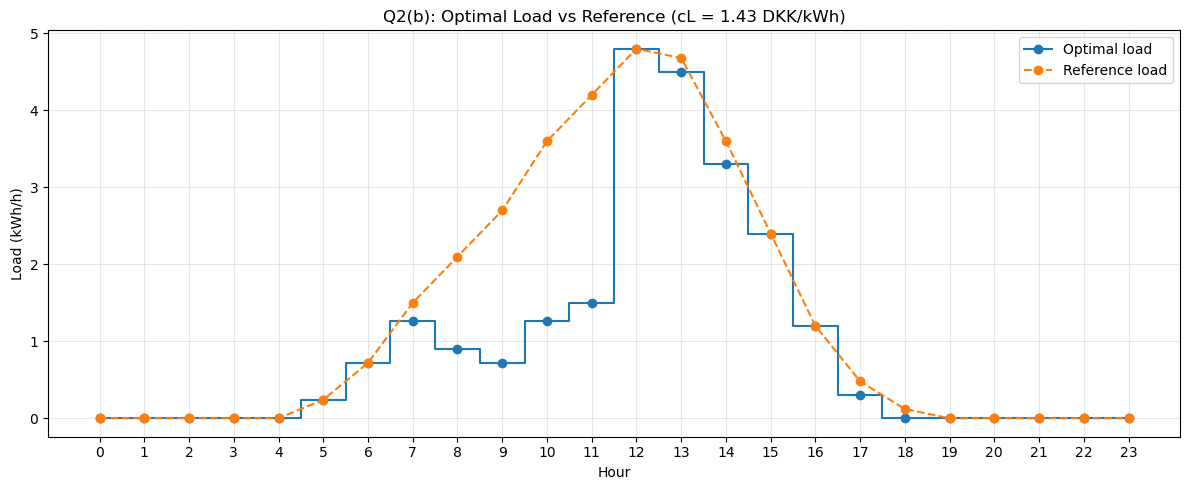

In [89]:
import matplotlib.pyplot as plt
hourly = results_B.hourly.copy()

hourly["reference"] = data.reference_load

plt.figure(figsize=(12, 5))

plt.step(
    hourly.index,
    hourly["load"],
    where="mid",
    marker="o",
    label="Optimal load"
)

plt.plot(
    hourly.index,
    hourly["reference"],
    marker="o",
    linestyle="--",
    label="Reference load"
)

plt.xlabel("Hour")
plt.ylabel("Load (kWh/h)")

plt.title(
    f"Q2(b): Optimal Load vs Reference "
    f"(cL = {model.cL:.2f} DKK/kWh)"
)

plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig(
    plots_dirs["Q2_linear"] / "Q2(b)_Optimal load vs Reference.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Check x_t

In [90]:
hourly["absolute_deviation"] = (
    hourly["load"]
    - hourly["reference"]
).abs()

hourly["difference"] = (
    hourly["deviation"]
    - hourly["absolute_deviation"]
)

display(
    hourly[
        [
            "load",
            "reference",
            "deviation",
            "absolute_deviation",
            "difference"
        ]
    ].round(6)
)

,load,reference,deviation,absolute_deviation,difference
hour,,,,,
0,0.00,0.00,0.00,0.00,0.0
1,0.00,0.00,0.00,0.00,0.0
2,0.00,0.00,0.00,0.00,0.0
3,0.00,0.00,0.00,0.00,0.0
4,0.00,0.00,0.00,0.00,0.0
5,0.24,0.24,0.00,0.00,0.0
6,0.72,0.72,0.00,0.00,0.0
7,1.26,1.50,0.24,0.24,0.0
8,0.90,2.10,1.20,1.20,0.0


### Calculate the metrics

In [91]:
absolute_deviation = (
    hourly["load"]
    - hourly["reference"]
).abs()

daily_energy = hourly["load"].sum()

total_deviation = absolute_deviation.sum()

total_disutility = (
    model.cL
    * total_deviation
)

procurement_cost = (
    (
        data.energy_price
        + data.import_tariff
    )
    * hourly["import"]
).sum() - (
    (
        data.energy_price
        - data.export_tariff
    )
    * hourly["export"]
).sum() + (
    data.pv_marginal_cost
    * hourly["pv"]
).sum()


metrics = pd.DataFrame({
    "Metric": [
        "Daily procurement cost (DKK)",
        "Total disutility (DKK)",
        "Daily energy consumed (kWh)",
        "Total absolute deviation (kWh)"
    ],
    "Value": [
        procurement_cost,
        total_disutility,
        daily_energy,
        total_deviation
    ]
})

display(metrics.round(4))

,Metric,Value
0,Daily procurement cost (DKK),31.1010
1,Total disutility (DKK),13.2132
2,Daily energy consumed (kWh),23.1000
3,Total absolute deviation (kWh),9.2400


The net cost is given by the summation of daily procurement cost and the total disutility cost. Since, here the total net cost of 44.31 is associated with the daily procument cost of 31.10 and total disutility of 13.21 for the energy consumption of 23.1 and the disutility (cost of deviation from the reference) of 9.24 units. 

### Save results

In [92]:
results_folder = results_dirs["Q2_linear"]

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

hourly.to_csv(
    results_folder / "Q2_b_base_hourly.csv"
)

metrics.to_csv(
    results_folder / "Q2_b_base_metrics.csv",
    index=False
)

print("Results saved to:")
print(results_folder)

Results saved to:
F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final\results\Q2_linear


### Check for c^L range

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Q2(b)(iv): Sensitivity analysis over cL
# ---------------------------------------------------------

# Choose values that cover low, intermediate, and high
# disutility sensitivity.
cL_values = np.array([
    0.10, 0.25, 0.50, 0.75, 1.00,
    1.25, 1.43, 1.50, 1.75, 2.00,  
    2.25, 2.50, 3.00, 3.50, 4.00, 
    4.25, 4.50, 5.00, 10.00 
])

sweep_results = []
hourly_schedules = {}

tol = 1e-6

for cL in cL_values:

    # Build and solve model
    model = LinearDisutilityModel(
        data,
        cL=cL,
        name=f"Q2_linear_cL_{cL:.2f}",
        verbose=False
    )

    model.build()
    result = model.solve()

    # Hourly solution
    h = result.hourly.copy()

    # Reference profile
    h["reference"] = data.reference_load

    # Absolute deviation
    h["absolute_deviation"] = (
        h["load"] - h["reference"]
    ).abs()

    # -----------------------------------------------------
    # Procurement cost
    # -----------------------------------------------------
    import_cost = np.sum(
        (data.energy_price + data.import_tariff)
        * h["import"]
    )

    export_revenue = np.sum(
        (data.energy_price - data.export_tariff)
        * h["export"]
    )

    pv_cost = np.sum(
        data.pv_marginal_cost * h["pv"]
    )

    procurement_cost = (
        import_cost
        - export_revenue
        + pv_cost
    )

    # -----------------------------------------------------
    # Requested metrics
    # -----------------------------------------------------
    total_disutility = (
        cL * h["absolute_deviation"].sum()
    )

    daily_energy = h["load"].sum()

    total_absolute_deviation = (
        h["absolute_deviation"].sum()
    )

    # -----------------------------------------------------
    # Load-bound hours
    # -----------------------------------------------------
    lower_bound_hours = np.sum(
        np.isclose(
            h["load"],
            data.load_min_kWh,
            atol=tol
        )
    )

    upper_bound_hours = np.sum(
        np.isclose(
            h["load"],
            data.load_max_kWh,
            atol=tol
        )
    )

    load_bound_hours = (
        lower_bound_hours + upper_bound_hours
    )

    # -----------------------------------------------------
    # Deviation linearization binding
    #
    # x_t should equal |L_t - reference_t|
    # whenever cL > 0.
    # -----------------------------------------------------
    deviation_binding_hours = np.sum(
        np.isclose(
            h["deviation"],
            h["absolute_deviation"],
            atol=tol
        )
    )

    # Store hourly schedule
    hourly_schedules[cL] = h.copy()

    # Store summary
    sweep_results.append({
        "cL": cL,
        "procurement_cost_DKK": procurement_cost,
        "total_disutility_DKK": total_disutility,
        "daily_energy_kWh": daily_energy,
        "total_absolute_deviation_kWh": total_absolute_deviation,
        "load_bound_hours": load_bound_hours,
        "lower_bound_hours": lower_bound_hours,
        "upper_bound_hours": upper_bound_hours,
        "deviation_bound_binding_hours": deviation_binding_hours
    })

sweep_df = pd.DataFrame(sweep_results)
"""
display(
    sweep_df.round(4)
)
"""
report_table = sweep_df[
    [
        "cL",
        "procurement_cost_DKK",
        "total_disutility_DKK",
        "daily_energy_kWh",
        "total_absolute_deviation_kWh",
        "deviation_bound_binding_hours"
    ]
].copy()

report_table.columns = [
    "cL (DKK/kWh)",
    "Procurement cost (DKK)",
    "Total disutility (DKK)",
    "Daily energy (kWh)",
    "Total absolute deviation (kWh)",
    "Deviation-bound hours"
]

display(report_table.round(4))

# Save sensitivity results table
report_table.round(4).to_csv(
    "results/Q2_linear/Q2_b_iv_sensitivity_table.csv",
    index=False
)

,cL (DKK/kWh),Procurement cost (DKK),Total disutility (DKK),Daily energy (kWh),Total absolute deviation (kWh),Deviation-bound hours
0,0.10,-1.470,3.2340,0.00,32.34,24
1,0.25,-1.470,8.0850,0.00,32.34,24
2,0.50,-1.470,16.1700,0.00,32.34,24
3,0.75,-1.470,24.2550,0.00,32.34,24
4,1.00,-1.470,32.3400,0.00,32.34,24
5,1.25,-1.470,40.4250,0.00,32.34,24
6,1.43,31.101,13.2132,23.10,9.24,24
7,1.50,31.806,13.1400,23.58,8.76,24
8,1.75,36.738,9.9750,26.64,5.70,24
9,2.00,44.058,3.9600,30.36,1.98,24


As we can see in this table it is clear that when c^L increase the cost of total disutility decrease so as to stay closer to the reference profile. However, on the other hand higher c^L means less load flexibility which leads to higher procurement cost. So the c^L value is trade of between procurement cost and disutility cost. At sufficiently large c^L (2.25) the cost of disutility becomes 0 that no longer change the load.

### Identify Optimal schedule changes

In [94]:
# ---------------------------------------------------------
# Identify changes in the optimal hourly schedule
# ---------------------------------------------------------

schedule_changes = []

previous_cL = None
previous_load = None

for cL in cL_values:

    h = hourly_schedules[cL]
    current_load = h["load"].to_numpy()

    if previous_load is not None:

        changed_hours = np.where(
            np.abs(current_load - previous_load) > 1e-5
        )[0]

        schedule_changes.append({
            "from_cL": previous_cL,
            "to_cL": cL,
            "number_of_changed_hours": len(changed_hours),
            "changed_hours": changed_hours.tolist()
        })

    previous_cL = cL
    previous_load = current_load

schedule_changes_df = pd.DataFrame(schedule_changes)

display(schedule_changes_df)

,from_cL,to_cL,number_of_changed_hours,changed_hours
0,0.10,0.25,0,[]
1,0.25,0.50,0,[]
2,0.50,0.75,0,[]
3,0.75,1.00,0,[]
4,1.00,1.25,0,[]
5,1.25,1.43,13,"[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]"
6,1.43,1.50,2,"[13, 14]"
7,1.50,1.75,3,"[7, 11, 18]"
8,1.75,2.00,3,"[8, 10, 17]"
9,2.00,2.25,1,[9]


The sensitivity occurs where 1.25 to 2.25 C^L range. Optimal schedule is changing substantially around the range of 1.25 to 1.43.

### Plot the sensitivity Analysis 

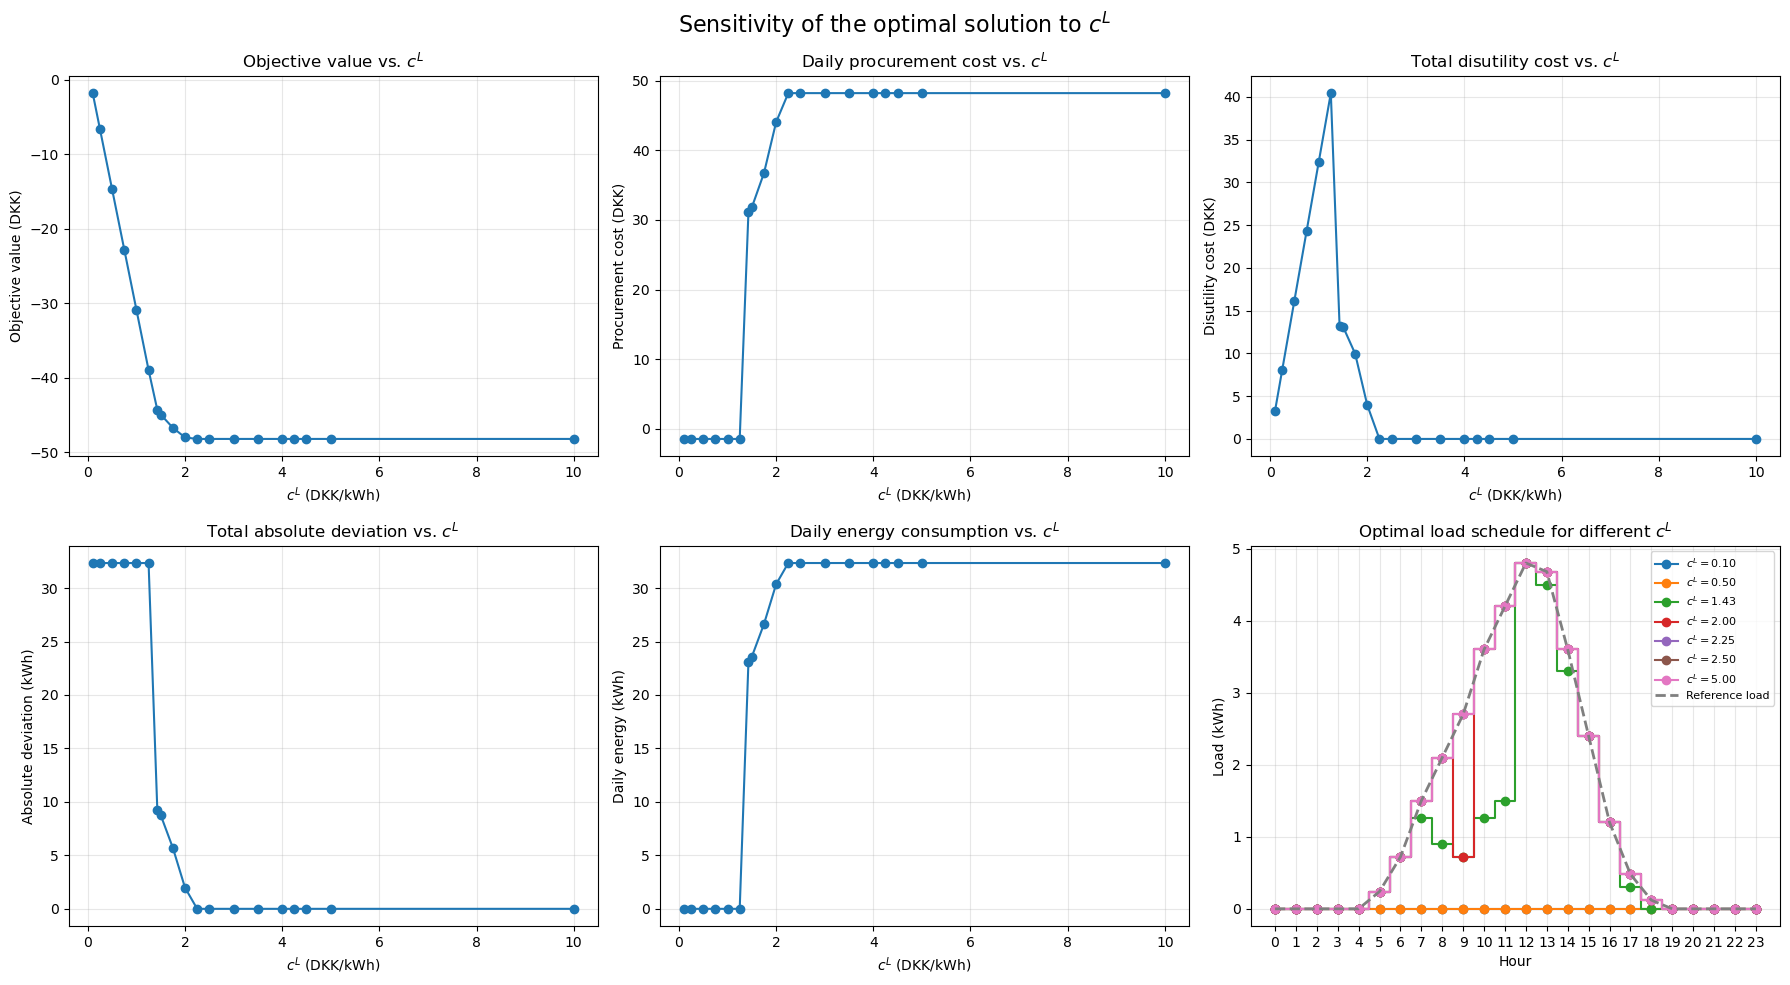

In [95]:
# ---------------------------------------------------------
# Q2(b)(iv): Combined sensitivity plots
# ---------------------------------------------------------

# Calculate net cost and objective value
sweep_df["net_cost_DKK"] = (
    sweep_df["procurement_cost_DKK"]
    + sweep_df["total_disutility_DKK"]
)

sweep_df["objective_DKK"] = -sweep_df["net_cost_DKK"]


fig, axes = plt.subplots(2, 3, figsize=(18, 10))


# =========================================================
# Plot 1: Objective value vs cL
# =========================================================

axes[0, 0].plot(
    sweep_df["cL"],
    sweep_df["objective_DKK"],
    marker="o"
)

axes[0, 0].set_xlabel(r"$c^L$ (DKK/kWh)")
axes[0, 0].set_ylabel("Objective value (DKK)")
axes[0, 0].set_title("Objective value vs. $c^L$")
axes[0, 0].grid(True, alpha=0.3)


# =========================================================
# Plot 2: Procurement cost vs cL
# =========================================================

axes[0, 1].plot(
    sweep_df["cL"],
    sweep_df["procurement_cost_DKK"],
    marker="o"
)

axes[0, 1].set_xlabel(r"$c^L$ (DKK/kWh)")
axes[0, 1].set_ylabel("Procurement cost (DKK)")
axes[0, 1].set_title("Daily procurement cost vs. $c^L$")
axes[0, 1].grid(True, alpha=0.3)


# =========================================================
# Plot 3: Disutility cost vs cL
# =========================================================

axes[0, 2].plot(
    sweep_df["cL"],
    sweep_df["total_disutility_DKK"],
    marker="o"
)

axes[0, 2].set_xlabel(r"$c^L$ (DKK/kWh)")
axes[0, 2].set_ylabel("Disutility cost (DKK)")
axes[0, 2].set_title("Total disutility cost vs. $c^L$")
axes[0, 2].grid(True, alpha=0.3)


# =========================================================
# Plot 4: Total absolute deviation vs cL
# =========================================================

axes[1, 0].plot(
    sweep_df["cL"],
    sweep_df["total_absolute_deviation_kWh"],
    marker="o"
)

axes[1, 0].set_xlabel(r"$c^L$ (DKK/kWh)")
axes[1, 0].set_ylabel("Absolute deviation (kWh)")
axes[1, 0].set_title("Total absolute deviation vs. $c^L$")
axes[1, 0].grid(True, alpha=0.3)


# =========================================================
# Plot 5: Daily energy consumption vs cL
# =========================================================

axes[1, 1].plot(
    sweep_df["cL"],
    sweep_df["daily_energy_kWh"],
    marker="o"
)

axes[1, 1].set_xlabel(r"$c^L$ (DKK/kWh)")
axes[1, 1].set_ylabel("Daily energy (kWh)")
axes[1, 1].set_title("Daily energy consumption vs. $c^L$")
axes[1, 1].grid(True, alpha=0.3)


# =========================================================
# Plot 6: Optimal schedules for selected cL values
# =========================================================

selected_cL = [
    cL_values[0],
    0.50,
    1.43,
    2.00,
    2.25,
    2.50,
    5.00,
]

for cL in selected_cL:

    # Make sure the selected value exists in the sweep
    if cL not in hourly_schedules:
        continue

    h = hourly_schedules[cL]

    axes[1, 2].step(
        h.index,
        h["load"],
        where="mid",
        marker="o",
        label=fr"$c^L={cL:.2f}$"
    )


# Reference profile
axes[1, 2].plot(
    data.hours,
    data.reference_load,
    linestyle="--",
    linewidth=2,
    label="Reference load"
)

axes[1, 2].set_xlabel("Hour")
axes[1, 2].set_ylabel("Load (kWh)")
axes[1, 2].set_title("Optimal load schedule for different $c^L$")
axes[1, 2].set_xticks(data.hours)
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].legend(fontsize=8)


# =========================================================
# Overall figure
# =========================================================

fig.suptitle(
    "Sensitivity of the optimal solution to $c^L$",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    plots_dirs["Q2_linear"] / "Q2(b)(iv).png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

As per the sensitivity analysis plots it is clear that low c^L is resulting in low energy consumption and low procurement cost along with high disutility cost. The higher c^L leads to highly penalize the deviation from the reference. As a result of that when c^L increase, absolute deviation and the disutility cost reduce. However, on the other hand high c^L tends to increase the procument cost. As in overall, when c^L increase the total cost is minimized and become stabilized at the point c^L=2.25. At this point optimal load profile equal to the reference point and the optimal schedule or the procument cost will not be further improved.  

### Effective price

In [96]:
price_table = pd.DataFrame({
    "hour": data.hours,
    "market_price": data.energy_price,
    "effective_import_price":
        data.energy_price + data.import_tariff,
    "effective_export_price":
        data.energy_price - data.export_tariff,
    "PV_marginal_cost":
        data.pv_marginal_cost
})

display(price_table.round(3))

,hour,market_price,effective_import_price,effective_export_price,PV_marginal_cost
0,0,1.10,1.60,0.70,1.41
1,1,1.05,1.55,0.65,1.41
2,2,1.00,1.50,0.60,1.41
3,3,0.90,1.40,0.50,1.41
4,4,0.85,1.35,0.45,1.41
5,5,1.01,1.51,0.61,1.41
6,6,1.05,1.55,0.65,1.41
7,7,1.20,1.70,0.80,1.41
8,8,1.40,1.90,1.00,1.41
9,9,1.60,2.10,1.20,1.41


As per the hourly price table effective import price is always higher than the export price. Furthermore, the optimal solution is based on the hourly price change as well

### Hours at the load bounds

In [97]:
# Examine the base case in detail

base_h = hourly_schedules[1.43].copy()

base_h["at_lower_bound"] = np.isclose(
    base_h["load"],
    data.load_min_kWh,
    atol=1e-6
)

base_h["at_upper_bound"] = np.isclose(
    base_h["load"],
    data.load_max_kWh,
    atol=1e-6
)

display(
    base_h[
        [
            "load",
            "reference",
            "absolute_deviation",
            "at_lower_bound",
            "at_upper_bound"
        ]
    ].round(4)
)

,load,reference,absolute_deviation,at_lower_bound,at_upper_bound
hour,,,,,
0,0.00,0.00,0.00,True,False
1,0.00,0.00,0.00,True,False
2,0.00,0.00,0.00,True,False
3,0.00,0.00,0.00,True,False
4,0.00,0.00,0.00,True,False
5,0.24,0.24,0.00,False,False
6,0.72,0.72,0.00,False,False
7,1.26,1.50,0.24,False,False
8,0.90,2.10,1.20,False,False


### Compare objective components

In [98]:
sweep_df["objective_check"] = -(
    sweep_df["procurement_cost_DKK"]
    + sweep_df["total_disutility_DKK"]
)

display(
    sweep_df[
        [
            "cL",
            "procurement_cost_DKK",
            "total_disutility_DKK",
            "objective_check"
        ]
    ].round(4)
)

,cL,procurement_cost_DKK,total_disutility_DKK,objective_check
0,0.10,-1.470,3.2340,-1.7640
1,0.25,-1.470,8.0850,-6.6150
2,0.50,-1.470,16.1700,-14.7000
3,0.75,-1.470,24.2550,-22.7850
4,1.00,-1.470,32.3400,-30.8700
5,1.25,-1.470,40.4250,-38.9550
6,1.43,31.101,13.2132,-44.3142
7,1.50,31.806,13.1400,-44.9460
8,1.75,36.738,9.9750,-46.7130
9,2.00,44.058,3.9600,-48.0180


# c. Quadratic Disutility

## Load Quadratic data

In [99]:
data = load_question(
    "Q2_quadratic",
    data_dir=repo / "data"
)

print(data.summary())

Case                 : Q2_quadratic
Consumer             : C_02_Q
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : None
Min daily energy     : None
Reference profile    : yes (32.3 kWh/day)
Disutility lin/quad  : None / 1.0
Battery              : no
Next-day forecasts   : yes


In [100]:
# Inspect parameters
print("Quadratic disutility cQ:",
      data.quadratic_disutility)

print("Import tariff:",
      data.import_tariff)

print("Export tariff:",
      data.export_tariff)

print("PV marginal cost:",
      data.pv_marginal_cost)

print("Load minimum:",
      data.load_min_kWh)

print("Load maximum:",
      data.load_max_kWh)

Quadratic disutility cQ: 1.0
Import tariff: 0.5
Export tariff: 0.4
PV marginal cost: 1.41
Load minimum: 0.0
Load maximum: 6.0


### Calculate effective price

In [101]:
effective_import_price = (
    data.energy_price + data.import_tariff
)

effective_export_price = (
    data.energy_price - data.export_tariff
)

price_table = pd.DataFrame({
    "hour": data.hours,
    "market_price": data.energy_price,
    "effective_import_price": effective_import_price,
    "effective_export_price": effective_export_price
})

display(price_table.round(3))

print(
    "Minimum effective export price:",
    effective_export_price.min()
)

assert np.all(effective_export_price > 0), \
    "The assumption p_t - tau_exp > 0 is violated."

,hour,market_price,effective_import_price,effective_export_price
0,0,1.10,1.60,0.70
1,1,1.05,1.55,0.65
2,2,1.00,1.50,0.60
3,3,0.90,1.40,0.50
4,4,0.85,1.35,0.45
5,5,1.01,1.51,0.61
6,6,1.05,1.55,0.65
7,7,1.20,1.70,0.80
8,8,1.40,1.90,1.00
9,9,1.60,2.10,1.20


Minimum effective export price: 0.44999999999999996


### Implement the Model

In [102]:
class QuadraticDisutilityModel(FlexibleConsumerModel):
    """
    Q2(c): Flexible consumer with quadratic disutility.

    Energy quantities are in kWh.
    Energy prices and PV marginal cost are in DKK/kWh.
    The quadratic disutility coefficient cQ is in DKK/kWh^2.
    """

    def __init__(
        self,
        data,
        cQ=None,
        name="Q2_quadratic",
        verbose=False
    ):
        super().__init__(
            data,
            name=name,
            verbose=verbose
        )

        if cQ is None:
            cQ = data.quadratic_disutility

        self.cQ = float(cQ)

        if self.cQ <= 0:
            raise ValueError(
                "cQ must be positive."
            )

        if data.reference_load is None:
            raise ValueError(
                "Reference load is required for Q2(c)."
            )

    def build(self):
        d = self.data
        m = self.m
        T = self.T

        # -------------------------------------------------
        # Decision variables
        # -------------------------------------------------

        L = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="load"
        )

        PV = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="pv"
        )

        P_imp = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="import"
        )

        P_exp = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="export"
        )

        self.var["load"] = L
        self.var["pv"] = PV
        self.var["import"] = P_imp
        self.var["export"] = P_exp

        # -------------------------------------------------
        # Effective import/export prices
        # -------------------------------------------------

        p_imp = (
            d.energy_price
            + d.import_tariff
        )

        p_exp = (
            d.energy_price
            - d.export_tariff
        )

        # -------------------------------------------------
        # Objective
        # -------------------------------------------------

        objective = gp.quicksum(
            -self.cQ
            * (
                L[t]
                - d.reference_load[t]
            ) ** 2

            - d.pv_marginal_cost * PV[t]

            - p_imp[t] * P_imp[t]

            + p_exp[t] * P_exp[t]

            for t in T
        )

        m.setObjective(
            objective,
            GRB.MAXIMIZE
        )

        # -------------------------------------------------
        # Constraints
        # -------------------------------------------------

        # Energy balance
        self.con["balance"] = m.addConstrs(
            PV[t]
            - L[t]
            - P_exp[t]
            + P_imp[t]
            == 0
            for t in T
        )

        # Load bounds
        self.con["load_min"] = m.addConstrs(
            L[t] >= d.load_min_kWh
            for t in T
        )

        self.con["load_max"] = m.addConstrs(
            L[t] <= d.load_max_kWh
            for t in T
        )

        # PV bounds
        self.con["pv_min"] = m.addConstrs(
            PV[t] >= 0
            for t in T
        )

        self.con["pv_max"] = m.addConstrs(
            PV[t] <= d.pv_available[t]
            for t in T
        )

        # Grid import/export bounds
        self.con["import_min"] = m.addConstrs(
            P_imp[t] >= 0
            for t in T
        )

        self.con["export_min"] = m.addConstrs(
            P_exp[t] >= 0
            for t in T
        )

        m.update()

        return self

### Solve base case

In [103]:
base_cQ = data.quadratic_disutility

model = QuadraticDisutilityModel(
    data,
    cQ=base_cQ,
    name="Q2_quadratic_base"
)

model.build()

results_C = model.solve()

print(results_C)

status: OPTIMAL | objective: -39.97 DKK
daily totals (kWh): load=22.8, pv=21.3, import=4.4, export=3.0


### Inspect hourly solution

In [104]:
hourly = results_C.hourly.copy()

hourly["reference"] = data.reference_load

hourly["deviation"] = (
    hourly["load"] - hourly["reference"]
)

hourly["squared_deviation"] = (
    hourly["deviation"] ** 2
)

display(
    hourly[
        [
            "load",
            "reference",
            "deviation",
            "squared_deviation",
            "pv",
            "import",
            "export"
        ]
    ].round(4)
)

,load,reference,deviation,squared_deviation,pv,import,export
hour,,,,,,,
0,0.000,0.00,0.000,0.0000,0.000,0.00,0.0
1,0.000,0.00,0.000,0.0000,0.000,0.00,0.0
2,0.000,0.00,0.000,0.0000,0.000,0.00,0.0
3,0.000,0.00,0.000,0.0000,0.000,0.00,0.0
4,0.000,0.00,0.000,0.0000,0.000,0.00,0.0
5,0.000,0.24,-0.240,0.0576,0.000,0.00,0.0
6,0.015,0.72,-0.705,0.4970,0.015,0.00,0.0
7,0.795,1.50,-0.705,0.4970,0.795,0.00,0.0
8,1.150,2.10,-0.950,0.9025,0.900,0.25,0.0


### Optimal load vs reference plot

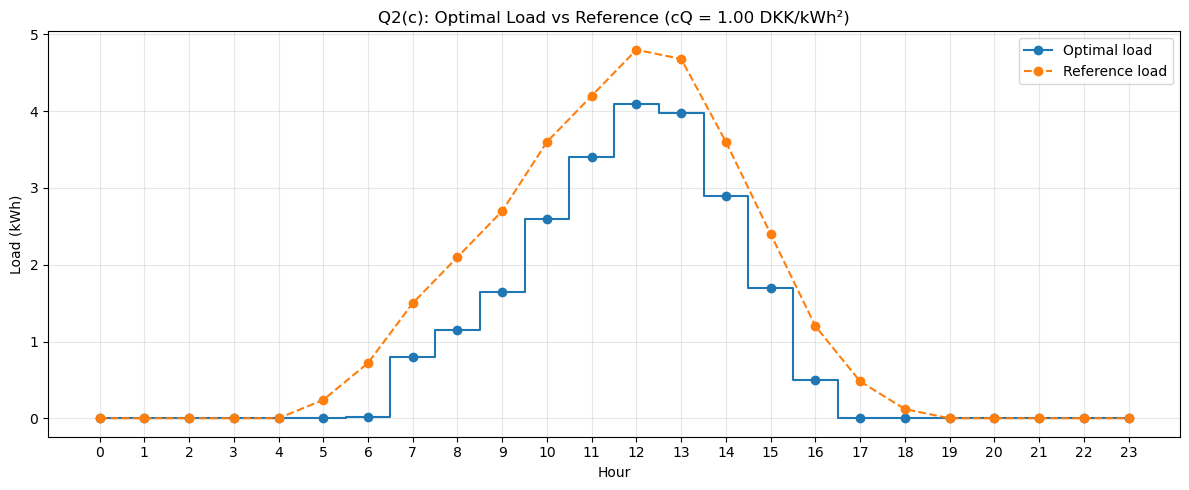

In [105]:
plt.figure(figsize=(12, 5))

plt.step(
    hourly.index,
    hourly["load"],
    where="mid",
    marker="o",
    label="Optimal load"
)

plt.plot(
    hourly.index,
    hourly["reference"],
    marker="o",
    linestyle="--",
    label="Reference load"
)

plt.xlabel("Hour")
plt.ylabel("Load (kWh)")
plt.title(
    f"Q2(c): Optimal Load vs Reference "
    f"(cQ = {base_cQ:.2f} DKK/kWh²)"
)

plt.xticks(hourly.index)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    plots_dirs["Q2_quadratic"] / "Q2_c_quadratic_vs_reference.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Calculate base case metrics

In [106]:
# ---------------------------------------------------------
# Base-case metrics
# ---------------------------------------------------------

import_cost = np.sum(
    effective_import_price * hourly["import"]
)

export_revenue = np.sum(
    effective_export_price * hourly["export"]
)

pv_cost = np.sum(
    data.pv_marginal_cost * hourly["pv"]
)

# Total procurement cost
procurement_cost = (
    import_cost
    - export_revenue
    + pv_cost
)

# Total squared deviation from the reference load
total_squared_deviation = np.sum(
    (
        hourly["load"]
        - hourly["reference"]
    ) ** 2
)

# Total quadratic disutility
total_disutility = (
    base_cQ
    * total_squared_deviation
)

# Total daily energy consumed
daily_energy = hourly["load"].sum()

# Number of hours at lower load bound
lower_bound_hours = np.sum(
    np.isclose(
        hourly["load"],
        data.load_min_kWh,
        atol=1e-6
    )
)

# Number of hours at upper load bound
upper_bound_hours = np.sum(
    np.isclose(
        hourly["load"],
        data.load_max_kWh,
        atol=1e-6
    )
)

# Total number of hours at either load bound
load_bound_hours = (
    lower_bound_hours
    + upper_bound_hours
)

# ---------------------------------------------------------
# Store metrics
# ---------------------------------------------------------

base_metrics = pd.DataFrame({
    "Metric": [
        "Daily procurement cost (DKK)",
        "Total quadratic disutility (DKK)",
        "Daily energy consumed (kWh)",
        "Total squared deviation (kWh^2)",
        "Hours at lower load bound",
        "Hours at upper load bound",
        "Total hours at load bounds"
    ],
    "Value": [
        procurement_cost,
        total_disutility,
        daily_energy,
        total_squared_deviation,
        lower_bound_hours,
        upper_bound_hours,
        load_bound_hours
    ]
})

display(base_metrics.round(4))

,Metric,Value
0,Daily procurement cost (DKK),32.5445
1,Total quadratic disutility (DKK),7.4266
2,Daily energy consumed (kWh),22.7650
3,Total squared deviation (kWh^2),7.4266
4,Hours at lower load bound,13.0000
5,Hours at upper load bound,0.0000
6,Total hours at load bounds,13.0000


### Sensitivity check

In [107]:
# ---------------------------------------------------------
# Q2(c) Sensitivity analysis
# ---------------------------------------------------------

cQ_values = np.array([
    0.05,
    0.10,
    0.20,
    0.30,
    0.50,
    0.75,
    1.00,
    1.25,
    1.50,
    2.00,
    2.50,
    3.00,
    4.00,
    5.00,
    7.50,
    10.00
])

sensitivity_rows_Q = []
hourly_schedules_Q = {}

for cQ in cQ_values:

    model_Q = QuadraticDisutilityModel(
        data,
        cQ=cQ,
        name=f"Q2_quadratic_cQ_{cQ:g}"
    )

    model_Q.build()

    results_Q = model_Q.solve()

    h = results_Q.hourly.copy()

    h["reference"] = data.reference_load

    # Squared deviation
    h["squared_deviation"] = (
        h["load"] - h["reference"]
    ) ** 2

    # Procurement cost
    import_cost_Q = np.sum(
        effective_import_price
        * h["import"]
    )

    export_revenue_Q = np.sum(
        effective_export_price
        * h["export"]
    )

    pv_cost_Q = np.sum(
        data.pv_marginal_cost
        * h["pv"]
    )

    procurement_cost_Q = (
        import_cost_Q
        - export_revenue_Q
        + pv_cost_Q
    )

    # Total squared deviation
    total_squared_deviation_Q = np.sum(
        h["squared_deviation"]
    )

    # Total quadratic disutility
    total_disutility_Q = (
        cQ
        * total_squared_deviation_Q
    )

    # Daily energy
    daily_energy_Q = h["load"].sum()

    # Load-bound hours
    lower_bound_hours_Q = np.sum(
        np.isclose(
            h["load"],
            data.load_min_kWh,
            atol=1e-6
        )
    )

    upper_bound_hours_Q = np.sum(
        np.isclose(
            h["load"],
            data.load_max_kWh,
            atol=1e-6
        )
    )

    load_bound_hours_Q = (
        lower_bound_hours_Q
        + upper_bound_hours_Q
    )

    # Store hourly schedule
    hourly_schedules_Q[cQ] = h

    # Store sensitivity results
    sensitivity_rows_Q.append({
        "cQ": cQ,
        "procurement_cost_DKK": procurement_cost_Q,
        "total_disutility_DKK": total_disutility_Q,
        "daily_energy_kWh": daily_energy_Q,
        "total_squared_deviation_kWh2":
            total_squared_deviation_Q,
        "load_bound_hours": load_bound_hours_Q
    })

# Convert to DataFrame
sweep_df_Q = pd.DataFrame(
    sensitivity_rows_Q
)

display(
    sweep_df_Q.round(4)
)

,cQ,procurement_cost_DKK,total_disutility_DKK,daily_energy_kWh,total_squared_deviation_kWh2,load_bound_hours
0,0.05,-1.4700,5.5237,0.0000,110.4732,24
1,0.10,-1.4700,11.0473,0.0000,110.4732,24
2,0.20,3.1196,16.8198,3.2550,84.0989,19
3,0.30,11.5271,14.7501,9.2133,49.1669,17
4,0.50,20.8510,12.3349,15.5400,24.6698,15
5,0.75,28.2319,9.3285,20.1400,12.4380,14
6,1.00,32.5445,7.4266,22.7650,7.4266,13
7,1.25,35.3941,6.0773,24.5120,4.8619,13
8,1.50,37.3080,5.1888,25.6867,3.4592,12
9,2.00,39.8484,3.9546,27.2600,1.9773,12


### Plot sensitivity results

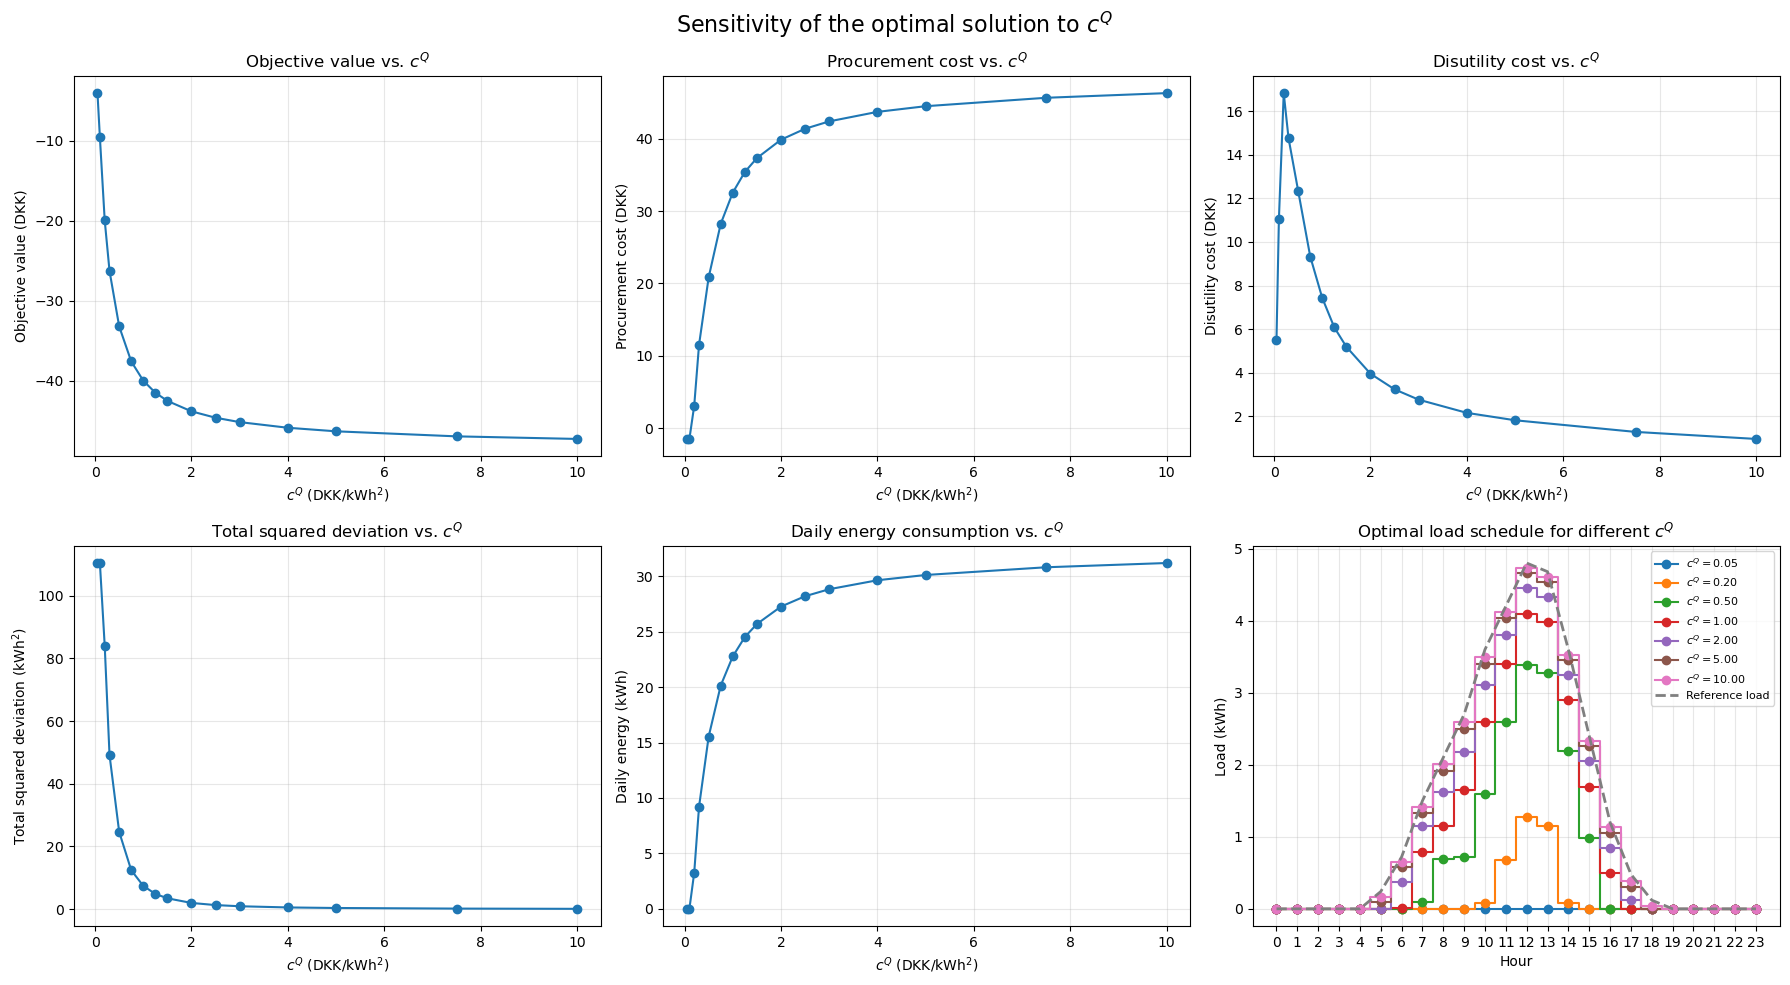

In [108]:
# ---------------------------------------------------------
# Q2(c): Combined sensitivity plots
# ---------------------------------------------------------

# Objective = -(procurement cost + disutility cost)
sweep_df_Q["net_cost_DKK"] = (
    sweep_df_Q["procurement_cost_DKK"]
    + sweep_df_Q["total_disutility_DKK"]
)

sweep_df_Q["objective_DKK"] = (
    -sweep_df_Q["net_cost_DKK"]
)


fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 10)
)

# ---------------------------------------------------------
# 1. Objective value
# ---------------------------------------------------------

axes[0, 0].plot(
    sweep_df_Q["cQ"],
    sweep_df_Q["objective_DKK"],
    marker="o"
)

axes[0, 0].set_xlabel(
    r"$c^Q$ (DKK/kWh$^2$)"
)

axes[0, 0].set_ylabel(
    "Objective value (DKK)"
)

axes[0, 0].set_title(
    r"Objective value vs. $c^Q$"
)

axes[0, 0].grid(
    True,
    alpha=0.3
)


# ---------------------------------------------------------
# 2. Procurement cost
# ---------------------------------------------------------

axes[0, 1].plot(
    sweep_df_Q["cQ"],
    sweep_df_Q["procurement_cost_DKK"],
    marker="o"
)

axes[0, 1].set_xlabel(
    r"$c^Q$ (DKK/kWh$^2$)"
)

axes[0, 1].set_ylabel(
    "Procurement cost (DKK)"
)

axes[0, 1].set_title(
    r"Procurement cost vs. $c^Q$"
)

axes[0, 1].grid(
    True,
    alpha=0.3
)


# ---------------------------------------------------------
# 3. Disutility cost
# ---------------------------------------------------------

axes[0, 2].plot(
    sweep_df_Q["cQ"],
    sweep_df_Q["total_disutility_DKK"],
    marker="o"
)

axes[0, 2].set_xlabel(
    r"$c^Q$ (DKK/kWh$^2$)"
)

axes[0, 2].set_ylabel(
    "Disutility cost (DKK)"
)

axes[0, 2].set_title(
    r"Disutility cost vs. $c^Q$"
)

axes[0, 2].grid(
    True,
    alpha=0.3
)


# ---------------------------------------------------------
# 4. Total squared deviation
# ---------------------------------------------------------

axes[1, 0].plot(
    sweep_df_Q["cQ"],
    sweep_df_Q["total_squared_deviation_kWh2"],
    marker="o"
)

axes[1, 0].set_xlabel(
    r"$c^Q$ (DKK/kWh$^2$)"
)

axes[1, 0].set_ylabel(
    r"Total squared deviation (kWh$^2$)"
)

axes[1, 0].set_title(
    r"Total squared deviation vs. $c^Q$"
)

axes[1, 0].grid(
    True,
    alpha=0.3
)


# ---------------------------------------------------------
# 5. Daily energy consumption
# ---------------------------------------------------------

axes[1, 1].plot(
    sweep_df_Q["cQ"],
    sweep_df_Q["daily_energy_kWh"],
    marker="o"
)

axes[1, 1].set_xlabel(
    r"$c^Q$ (DKK/kWh$^2$)"
)

axes[1, 1].set_ylabel(
    "Daily energy (kWh)"
)

axes[1, 1].set_title(
    r"Daily energy consumption vs. $c^Q$"
)

axes[1, 1].grid(
    True,
    alpha=0.3
)


# ---------------------------------------------------------
# 6. Optimal load schedules
# ---------------------------------------------------------

selected_cQ = [
    cQ_values[0],
    0.20,
    0.50,
    1.00,
    2.00,
    5.00,
    10.00
]

for cQ in selected_cQ:

    if cQ not in hourly_schedules_Q:
        continue

    h = hourly_schedules_Q[cQ]

    axes[1, 2].step(
        h.index,
        h["load"],
        where="mid",
        marker="o",
        label=fr"$c^Q={cQ:.2f}$"
    )


# Reference load
axes[1, 2].plot(
    data.hours,
    data.reference_load,
    linestyle="--",
    linewidth=2,
    label="Reference load"
)

axes[1, 2].set_xlabel(
    "Hour"
)

axes[1, 2].set_ylabel(
    "Load (kWh)"
)

axes[1, 2].set_title(
    r"Optimal load schedule for different $c^Q$"
)

axes[1, 2].set_xticks(
    data.hours
)

axes[1, 2].grid(
    True,
    alpha=0.3
)

axes[1, 2].legend(
    fontsize=8
)


# ---------------------------------------------------------
# Overall title
# ---------------------------------------------------------

fig.suptitle(
    r"Sensitivity of the optimal solution to $c^Q$",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    plots_dirs["Q2_quadratic"] / "Q2(c)_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Identify the threshold point

In [109]:
# ---------------------------------------------------------
# Identify changes in optimal hourly schedule
# ---------------------------------------------------------

schedule_changes_Q = []

previous_cQ = None
previous_load = None

for cQ in cQ_values:

    h = hourly_schedules_Q[cQ]

    current_load = h["load"].to_numpy()

    if previous_load is not None:

        changed_hours = np.where(
            np.abs(
                current_load - previous_load
            ) > 1e-5
        )[0]

        schedule_changes_Q.append({
            "from_cQ": previous_cQ,
            "to_cQ": cQ,
            "number_of_changed_hours":
                len(changed_hours),
            "changed_hours":
                changed_hours.tolist()
        })

    previous_cQ = cQ
    previous_load = current_load

schedule_changes_df_Q = pd.DataFrame(
    schedule_changes_Q
)

display(schedule_changes_df_Q)

,from_cQ,to_cQ,number_of_changed_hours,changed_hours
0,0.05,0.10,0,[]
1,0.10,0.20,5,"[10, 11, 12, 13, 14]"
2,0.20,0.30,7,"[9, 10, 11, 12, 13, 14, 15]"
3,0.30,0.50,9,"[7, 8, 9, 10, 11, 12, 13, 14, 15]"
4,0.50,0.75,10,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16]"
5,0.75,1.00,11,"[6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]"
6,1.00,1.25,11,"[6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]"
7,1.25,1.50,12,"[6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]"
8,1.50,2.00,12,"[6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]"
9,2.00,2.50,12,"[6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]"


### Save results

In [110]:
results_folder = results_dirs["Q2_quadratic"]

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Base case
hourly.to_csv(
    results_folder / "Q2_c_base_hourly.csv"
)

base_metrics.to_csv(
    results_folder / "Q2_c_base_metrics.csv",
    index=False
)

# Sensitivity
sweep_df_Q.to_csv(
    results_folder / "Q2_c_sensitivity.csv",
    index=False
)


print(
    "Results saved to:",
    results_folder
)

Results saved to: F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final\results\Q2_quadratic


## 2d. Multimodel comparison

In [111]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Selected scenarios for the model comparison
# ---------------------------------------------------------

selected_cL = [1.00, 1.43, 1.75, 2.25]
selected_cQ = [0.50, 1.00, 2.00, 5.00]

comparison_rows = []

# ---------------------------------------------------------
# Linear disutility model
# ---------------------------------------------------------

for cL in selected_cL:

    h = hourly_schedules[cL].copy()

    # Deviations from reference
    abs_dev = (h["load"] - h["reference"]).abs()
    #sq_dev = (h["load"] - h["reference"]) ** 2

    # Metrics
    daily_energy = h["load"].sum()
    total_abs_dev = abs_dev.sum()
    #total_sq_dev = sq_dev.sum()

    procurement_cost = (
        ((data.energy_price + data.import_tariff) * h["import"]).sum()
        - ((data.energy_price - data.export_tariff) * h["export"]).sum()
        + (data.pv_marginal_cost * h["pv"]).sum()
    )

    total_disutility = cL * total_abs_dev
    objective = -(procurement_cost + total_disutility)

    # Load-bound hours
    lower_bound_hours = np.sum(
        np.isclose(h["load"], data.load_min_kWh, atol=1e-6)
    )
    upper_bound_hours = np.sum(
        np.isclose(h["load"], data.load_max_kWh, atol=1e-6)
    )

    comparison_rows.append({
        "Model": "Linear",
        "Parameter": cL,
        "Objective_DKK": objective,
        "Procurement_cost_DKK": procurement_cost,
        "Disutility_DKK": total_disutility,
        "Absolute_deviation_kWh": total_abs_dev,
        #"Squared_deviation_kWh2": total_sq_dev,
        "Daily_energy_kWh": daily_energy,
        "Lower_bound_hours": lower_bound_hours,
        "Upper_bound_hours": upper_bound_hours,
    })


# ---------------------------------------------------------
# Quadratic disutility model
# ---------------------------------------------------------

for cQ in selected_cQ:

    h = hourly_schedules_Q[cQ].copy()

    # Deviations from reference
    #abs_dev = (h["load"] - h["reference"]).abs()
    sq_dev = (h["load"] - h["reference"]) ** 2

    # Metrics
    daily_energy = h["load"].sum()
    #total_abs_dev = abs_dev.sum()
    total_sq_dev = sq_dev.sum()

    procurement_cost = (
        ((data.energy_price + data.import_tariff) * h["import"]).sum()
        - ((data.energy_price - data.export_tariff) * h["export"]).sum()
        + (data.pv_marginal_cost * h["pv"]).sum()
    )

    total_disutility = cQ * total_sq_dev
    objective = -(procurement_cost + total_disutility)

    # Load-bound hours
    lower_bound_hours = np.sum(
        np.isclose(h["load"], data.load_min_kWh, atol=1e-6)
    )
    upper_bound_hours = np.sum(
        np.isclose(h["load"], data.load_max_kWh, atol=1e-6)
    )

    comparison_rows.append({
        "Model": "Quadratic",
        "Parameter": cQ,
        "Objective_DKK": objective,
        "Procurement_cost_DKK": procurement_cost,
        "Disutility_DKK": total_disutility,
        "Squared_deviation_kWh2": total_sq_dev,
        "Daily_energy_kWh": daily_energy,
        "Lower_bound_hours": lower_bound_hours,
        "Upper_bound_hours": upper_bound_hours,
    })


# ---------------------------------------------------------
# Create comparison table
# ---------------------------------------------------------

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df.round(4))

,Model,Parameter,Objective_DKK,Procurement_cost_DKK,Disutility_DKK,Absolute_deviation_kWh,Daily_energy_kWh,Lower_bound_hours,Upper_bound_hours,Squared_deviation_kWh2
0,Linear,1.00,-30.8700,-1.4700,32.3400,32.34,0.000,24,0,NaN
1,Linear,1.43,-44.3142,31.1010,13.2132,9.24,23.100,11,0,NaN
2,Linear,1.75,-46.7130,36.7380,9.9750,5.70,26.640,10,0,NaN
3,Linear,2.25,-48.2160,48.2160,0.0000,0.00,32.340,10,0,NaN
4,Quadratic,0.50,-33.1859,20.8510,12.3349,NaN,15.540,15,0,24.6698
5,Quadratic,1.00,-39.9710,32.5445,7.4266,NaN,22.765,13,0,7.4266
6,Quadratic,2.00,-43.8030,39.8484,3.9546,NaN,27.260,12,0,1.9773
7,Quadratic,5.00,-46.2979,44.4757,1.8221,NaN,30.110,11,0,0.3644


## e. Temporal coupling

e (ii)

In [112]:
from gurobipy import GRB
import gurobipy as gp


class TemporallyCoupledDisutilityModel(FlexibleConsumerModel):
    """
    Q2(d): Flexible consumer with temporally coupled quadratic disutility.

    Disutility:
        cQ * sum_t (L_t - L_ref_t)^2
        + gamma * sum_{t=2}^{24}
          ((L_t - L_ref_t) + (L_{t-1} - L_ref_{t-1}))^2

    Units:
        cQ    : DKK/kWh^2
        gamma : DKK/kWh^2
        load  : kWh
    """

    def __init__(
        self,
        data,
        cQ=None,
        gamma=0.25,
        name="Q2_temporal",
        verbose=False
    ):
        super().__init__(data, name=name, verbose=verbose)

        # Use the Q2(c) quadratic coefficient by default
        if cQ is None:
            cQ = data.quadratic_disutility

        self.cQ = float(cQ)
        self.gamma = float(gamma)

        if self.cQ <= 0:
            raise ValueError("cQ must be positive.")

        if self.gamma < 0:
            raise ValueError("gamma must be non-negative.")

        if data.reference_load is None:
            raise ValueError(
                "Reference load is required for the temporally "
                "coupled disutility model."
            )

    def build(self):
        d = self.data
        m = self.m
        T = self.T

        # ---------------------------------------------------------
        # Decision variables
        # ---------------------------------------------------------

        L = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="load"
        )

        PV = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="pv"
        )

        P_imp = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="import"
        )

        P_exp = m.addVars(
            T,
            lb=-GRB.INFINITY,
            vtype=GRB.CONTINUOUS,
            name="export"
        )

        # Store variables so that results.hourly contains them
        self.var["load"] = L
        self.var["pv"] = PV
        self.var["import"] = P_imp
        self.var["export"] = P_exp

        # ---------------------------------------------------------
        # Effective import/export prices
        # ---------------------------------------------------------

        p_imp = d.energy_price + d.import_tariff
        p_exp = d.energy_price - d.export_tariff

        # ---------------------------------------------------------
        # Deviations from reference
        # ---------------------------------------------------------

        deviation = {
            t: L[t] - d.reference_load[t]
            for t in T
        }

        # ---------------------------------------------------------
        # Objective
        #
        # Maximize negative total cost:
        #
        #   procurement cost
        # + separable quadratic disutility
        # + temporal coupling disutility
        # ---------------------------------------------------------

        separable_disutility = gp.quicksum(
            self.cQ * deviation[t] ** 2
            for t in T
        )

        temporal_disutility = gp.quicksum(
            self.gamma
            * (deviation[t] + deviation[t - 1]) ** 2
            for t in T
            if t > 0
        )

        procurement_cost = gp.quicksum(
            d.pv_marginal_cost * PV[t]
            + p_imp[t] * P_imp[t]
            - p_exp[t] * P_exp[t]
            for t in T
        )

        m.setObjective(
            -procurement_cost
            -separable_disutility
            -temporal_disutility,
            GRB.MAXIMIZE
        )

        # ---------------------------------------------------------
        # Energy balance
        # ---------------------------------------------------------

        self.con["balance"] = m.addConstrs(
            PV[t]
            - L[t]
            - P_exp[t]
            + P_imp[t]
            == 0
            for t in T
        )

        # ---------------------------------------------------------
        # Load bounds
        # ---------------------------------------------------------

        self.con["load_min"] = m.addConstrs(
            L[t] >= d.load_min_kWh
            for t in T
        )

        self.con["load_max"] = m.addConstrs(
            L[t] <= d.load_max_kWh
            for t in T
        )

        # ---------------------------------------------------------
        # PV bounds
        # ---------------------------------------------------------

        self.con["pv_min"] = m.addConstrs(
            PV[t] >= 0
            for t in T
        )

        self.con["pv_max"] = m.addConstrs(
            PV[t] <= d.pv_available[t]
            for t in T
        )

        # ---------------------------------------------------------
        # Grid import/export bounds
        # ---------------------------------------------------------

        self.con["import_min"] = m.addConstrs(
            P_imp[t] >= 0
            for t in T
        )

        self.con["export_min"] = m.addConstrs(
            P_exp[t] >= 0
            for t in T
        )

        m.update()

        return self

e(iii)

In [113]:
# ---------------------------------------------------------
# Q2(e): Base case
# ---------------------------------------------------------

cQ_base = 1.0
gamma_base = 0.25

model_E = (
    TemporallyCoupledDisutilityModel(
        data,
        cQ=cQ_base,
        gamma=gamma_base,
        name="Q2_temporal"
    )
    .build()
)

results_E = model_E.solve()

print(results_E)

status: OPTIMAL | objective: -43.76 DKK
daily totals (kWh): load=27.2, pv=23.9, import=6.3, export=3.0


In [114]:
hourly_E = results_E.hourly.copy()

hourly_E.head()

,price,pv_available,reference_load,load,pv,import,export,dual_balance,dual_load_min,dual_load_max,dual_pv_min,dual_pv_max,dual_import_min,dual_export_min
hour,,,,,,,,,,,,,,
0,1.10,0.0,0.0,0.0,0.0,0.0,0.0,-1.60,-1.60,0.0,-0.00,0.19,-0.0,-0.9
1,1.05,0.0,0.0,0.0,0.0,0.0,0.0,-1.55,-1.55,0.0,-0.00,0.14,-0.0,-0.9
2,1.00,0.0,0.0,0.0,0.0,0.0,0.0,-1.50,-1.50,0.0,-0.00,0.09,-0.0,-0.9
3,0.90,0.0,0.0,0.0,0.0,0.0,0.0,-1.40,-1.40,0.0,-0.01,0.00,-0.0,-0.9
4,0.85,0.0,0.0,0.0,0.0,0.0,0.0,-1.35,-1.23,0.0,-0.06,0.00,-0.0,-0.9


In [115]:
# Deviation from reference
hourly_E["deviation"] = (
    hourly_E["load"] - data.reference_load
)

# Separable quadratic component
hourly_E["separable_disutility"] = (
    model_E.cQ * hourly_E["deviation"] ** 2
)

# Temporal coupling component
hourly_E["temporal_disutility"] = 0.0

for t in range(1, len(hourly_E)):
    hourly_E.loc[t, "temporal_disutility"] = (
        model_E.gamma
        * (
            hourly_E.loc[t, "deviation"]
            + hourly_E.loc[t - 1, "deviation"]
        ) ** 2
    )

total_separable = hourly_E["separable_disutility"].sum()
total_temporal = hourly_E["temporal_disutility"].sum()
total_disutility = total_separable + total_temporal

print(f"Separable quadratic disutility: {total_separable:.4f} DKK")
print(f"Temporal coupling disutility:   {total_temporal:.4f} DKK")
print(f"Total disutility:                {total_disutility:.4f} DKK")

Separable quadratic disutility: 2.0260 DKK
Temporal coupling disutility:   1.9721 DKK
Total disutility:                3.9982 DKK


In [116]:
# Add the reference load to the results table
hourly_E["reference"] = data.reference_load

# Previous-hour deviation
hourly_E["previous_deviation"] = (
    hourly_E["deviation"].shift(1)
)

# Sum of consecutive deviations
hourly_E["consecutive_deviation_sum"] = (
    hourly_E["deviation"]
    + hourly_E["previous_deviation"]
)

# Display the relevant columns
display(
    hourly_E[
        [
            "load",
            "reference",
            "deviation",
            "previous_deviation",
            "consecutive_deviation_sum",
            "temporal_disutility"
        ]
    ].round(4)
)

,load,reference,deviation,previous_deviation,consecutive_deviation_sum,temporal_disutility
hour,,,,,,
0,0.0000,0.00,0.0000,NaN,NaN,0.0000
1,0.0000,0.00,0.0000,0.0000,0.0000,0.0000
2,0.0000,0.00,0.0000,0.0000,0.0000,0.0000
3,0.0000,0.00,0.0000,0.0000,0.0000,0.0000
4,0.0000,0.00,0.0000,0.0000,0.0000,0.0000
5,0.0000,0.24,-0.2400,0.0000,-0.2400,0.0144
6,0.3443,0.72,-0.3757,-0.2400,-0.6157,0.0948
7,1.1743,1.50,-0.3257,-0.3757,-0.7014,0.1230
8,1.6097,2.10,-0.4903,-0.3257,-0.8159,0.1664


In [117]:
print("Objective:", round(results_E.objective, 4))
print("Daily load:", round(hourly_E["load"].sum(), 4))
print("Daily PV:", round(hourly_E["pv"].sum(), 4))
print("Daily import:", round(hourly_E["import"].sum(), 4))
print("Daily export:", round(hourly_E["export"].sum(), 4))

print("Total absolute deviation:",
      round(hourly_E["deviation"].abs().sum(), 4))

print("Maximum absolute deviation:",
      round(hourly_E["deviation"].abs().max(), 4))

print("Separable disutility:",
      round(hourly_E["separable_disutility"].sum(), 4))

print("Temporal disutility:",
      round(hourly_E["temporal_disutility"].sum(), 4))

Objective: -43.7561
Daily load: 27.209
Daily PV: 23.9151
Daily import: 6.2939
Daily export: 3.0
Total absolute deviation: 5.131
Maximum absolute deviation: 0.5328
Separable disutility: 2.026
Temporal disutility: 1.9721


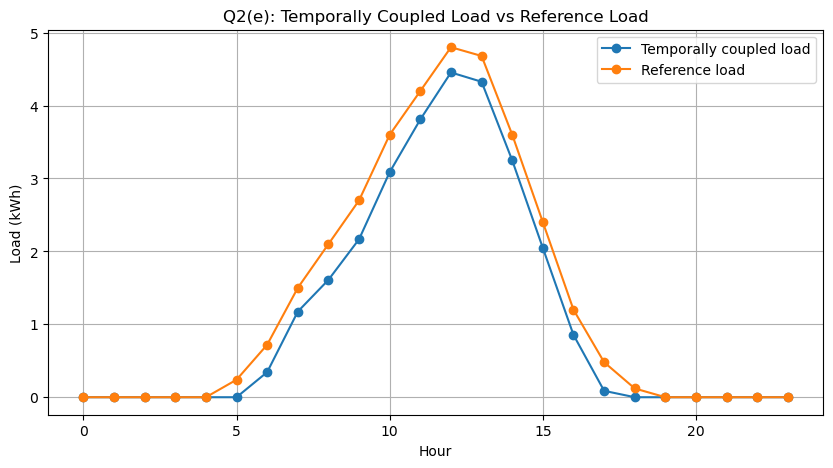

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_E.index,
    hourly_E["load"],
    marker="o",
    label="Temporally coupled load"
)

plt.plot(
    hourly_E.index,
    hourly_E["reference"],
    marker="o",
    label="Reference load"
)

plt.xlabel("Hour")
plt.ylabel("Load (kWh)")
plt.title("Q2(e): Temporally Coupled Load vs Reference Load")
plt.legend()
plt.grid(True)
plt.savefig(
    plots_dirs["Q2_temporal"] / "Q2_e_Temporal_vs_reference.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

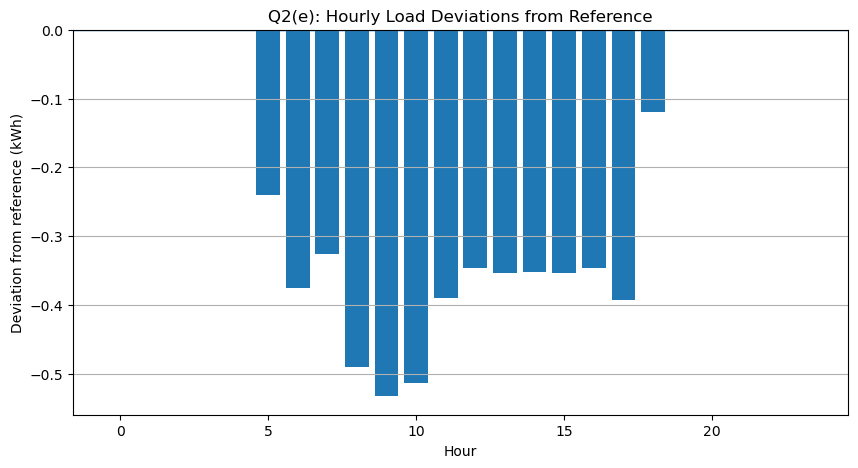

In [119]:
plt.figure(figsize=(10, 5))

plt.bar(
    hourly_E.index,
    hourly_E["deviation"]
)

plt.axhline(0, linewidth=1)

plt.xlabel("Hour")
plt.ylabel("Deviation from reference (kWh)")
plt.title("Q2(e): Hourly Load Deviations from Reference")
plt.grid(True, axis="y")
plt.show()

In [120]:
# Parameters used in the three solved models
cL_B = 1.43
cQ_C = 1.0
cQ_E = 1.0
gamma_E = 0.25

p_imp = data.energy_price + data.import_tariff
p_exp = data.energy_price - data.export_tariff


def calculate_procurement_cost(results):
    hourly = results.hourly

    pv_cost = (
        data.pv_marginal_cost * hourly["pv"]
    ).sum()

    import_cost = (
        p_imp * hourly["import"]
    ).sum()

    export_revenue = (
        p_exp * hourly["export"]
    ).sum()

    return pv_cost + import_cost - export_revenue


# -------------------------
# Q2(b) Linear
# -------------------------
dev_B = results_B.hourly["load"] - data.reference_load

proc_B = calculate_procurement_cost(results_B)
dis_B = cL_B * dev_B.abs().sum()


# -------------------------
# Q2(c) Quadratic
# -------------------------
dev_C = results_C.hourly["load"] - data.reference_load
sqrd_dev=dev_C**2
proc_C = calculate_procurement_cost(results_C)
dis_C = cQ_C * (sqrd_dev).sum()


# -------------------------
# Q2(e) Temporal
# -------------------------
dev_E = results_E.hourly["load"] - data.reference_load

proc_E = calculate_procurement_cost(results_E)

separable_E = cQ_E * (dev_E ** 2).sum()

temporal_E = gamma_E * sum(
    (dev_E.iloc[t] + dev_E.iloc[t-1]) ** 2
    for t in range(1, len(dev_E))
)

dis_E = separable_E + temporal_E


# -------------------------
# Comparison table
# -------------------------
comparison = pd.DataFrame({
    "Model": [
        "Q2(b) Linear",
        "Q2(c) Quadratic",
        "Q2(e) Temporal"
    ],

    "Objective (DKK)": [
        results_B.objective,
        results_C.objective,
        results_E.objective
    ],

    "Procurement cost (DKK)": [
        proc_B,
        proc_C,
        proc_E
    ],

    "Disutility cost (DKK)": [
        dis_B,
        dis_C,
        dis_E
    ],

    "Daily load (kWh)": [
        results_B.hourly["load"].sum(),
        results_C.hourly["load"].sum(),
        results_E.hourly["load"].sum()
    ],

    "Total absolute deviation (kWh)": [
        dev_B.abs().sum(),
        dev_C.abs().sum(),
        dev_E.abs().sum()
    ],

    "Maximum absolute deviation (kWh)": [
        dev_B.abs().max(),
        dev_C.abs().max(),
        dev_E.abs().max()
    ]
})

display(comparison.round(4))

,Model,Objective (DKK),Procurement cost (DKK),Disutility cost (DKK),Daily load (kWh),Total absolute deviation (kWh),Maximum absolute deviation (kWh)
0,Q2(b) Linear,-44.3142,31.1010,13.2132,23.100,9.240,2.7000
1,Q2(c) Quadratic,-39.9710,32.5445,7.4266,22.765,9.575,1.0500
2,Q2(e) Temporal,-43.7561,39.7579,3.9982,27.209,5.131,0.5328


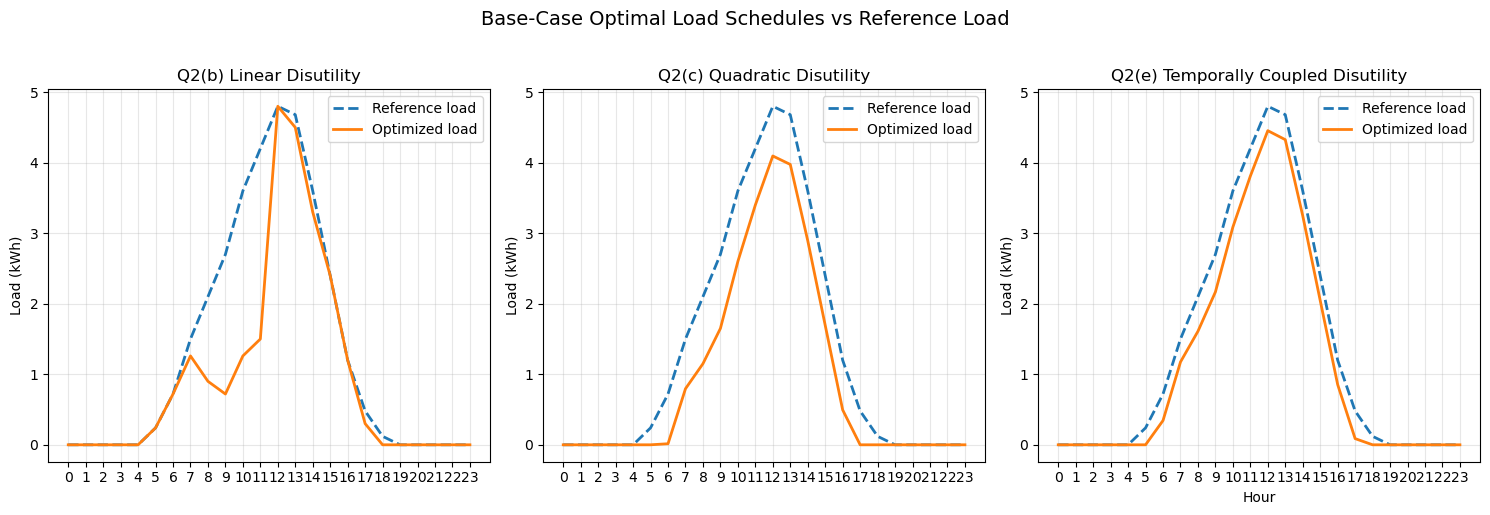

In [121]:
import matplotlib.pyplot as plt

hours = range(24)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True)

models = [
    (results_B, "Q2(b) Linear Disutility"),
    (results_C, "Q2(c) Quadratic Disutility"),
    (results_E, "Q2(e) Temporally Coupled Disutility")
]

for ax, (result, title) in zip(axes, models):
    ax.plot(
        hours,
        data.reference_load,
        linestyle="--",
        linewidth=2,
        label="Reference load"
    )
    
    ax.plot(
        hours,
        result.hourly["load"],
        linewidth=2,
        label="Optimized load"
    )
    
    ax.set_title(title)
    ax.set_ylabel("Load (kWh)")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Hour")
axes[-1].set_xticks(hours)

fig.suptitle(
    "Base-Case Optimal Load Schedules vs Reference Load",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.savefig(
    plots_dirs["Q2_temporal"] / "Q2_b_c_e_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Save results

In [122]:
from pathlib import Path
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Q2(e): Save existing temporal-model results
# ---------------------------------------------------------

results_folder_E = results_dirs["Q2_temporal"]
plots_folder_E = plots_dirs["Q2_temporal"]

results_folder_E.mkdir(parents=True, exist_ok=True)
plots_folder_E.mkdir(parents=True, exist_ok=True)

# Use the existing solution
hourly_E = results_E.hourly.copy()

# Add reference load and deviations
hourly_E["reference"] = data.reference_load
hourly_E["deviation"] = (
    hourly_E["load"] - hourly_E["reference"]
)
hourly_E["absolute_deviation"] = hourly_E["deviation"].abs()

# Calculate costs using the parameters already used for Q2(d)
p_imp_E = data.energy_price + data.import_tariff
p_exp_E = data.energy_price - data.export_tariff

procurement_E = (
    (data.pv_marginal_cost * hourly_E["pv"]).sum()
    + (p_imp_E * hourly_E["import"]).sum()
    - (p_exp_E * hourly_E["export"]).sum()
)

separable_disutility_E = (
    cQ_base * hourly_E["deviation"].pow(2).sum()
)

temporal_disutility_E = gamma_base * sum(
    (
        hourly_E["deviation"].iloc[t]
        + hourly_E["deviation"].iloc[t - 1]
    ) ** 2
    for t in range(1, len(hourly_E))
)

total_disutility_E = (
    separable_disutility_E + temporal_disutility_E
)

tol = 1e-6

# Summary metrics
metrics_E = pd.DataFrame([{
    "Objective_DKK": results_E.objective,
    "Procurement_cost_DKK": procurement_E,
    "Separable_disutility_DKK": separable_disutility_E,
    "Temporal_disutility_DKK": temporal_disutility_E,
    "Total_disutility_DKK": total_disutility_E,
    "Daily_load_kWh": hourly_E["load"].sum(),
    "Total_absolute_deviation_kWh": hourly_E["absolute_deviation"].sum(),
    "Maximum_absolute_deviation_kWh": hourly_E["absolute_deviation"].max(),
    "Hours_at_lower_bound": np.isclose(
        hourly_E["load"], data.load_min_kWh, atol=tol
    ).sum(),
    "Hours_at_upper_bound": np.isclose(
        hourly_E["load"], data.load_max_kWh, atol=tol
    ).sum(),
    "cQ": cQ_base,
    "gamma": gamma_base
}])

# Save tables
hourly_E.to_csv(
    results_folder_E / "Q2_e_base_hourly.csv",
    index=True,
    index_label="Hour"
)

metrics_E.to_csv(
    results_folder_E / "Q2_e_base_metrics.csv",
    index=False
)

# Save the parameters separately for reproducibility
pd.DataFrame([{
    "cQ_DKK_per_kWh2": cQ_base,
    "gamma_DKK_per_kWh2": gamma_base
}]).to_csv(
    results_folder_E / "Q2_e_parameters.csv",
    index=False
)

print("Temporal-model tables saved to:", results_folder_E)
display(metrics_E.round(4))

Temporal-model tables saved to: F:\academic\MSc Denmark\Fall 2\46750 Optimization\Assignment\assignment 01 final\results\Q2_temporal


,Objective_DKK,Procurement_cost_DKK,Separable_disutility_DKK,Temporal_disutility_DKK,Total_disutility_DKK,Daily_load_kWh,Total_absolute_deviation_kWh,Maximum_absolute_deviation_kWh,Hours_at_lower_bound,Hours_at_upper_bound,cQ,gamma
0,-43.7561,39.7579,2.026,1.9721,3.9982,27.209,5.131,0.5328,12,0,1.0,0.25


In [123]:
# Save the existing Q2(b), Q2(c), and Q2(e) comparison
comparison.to_csv(
    results_folder_E / "Q2_b_c_e_comparison.csv",
    index=False
)

print("Comparison table saved.")

Comparison table saved.


e (iv) Experiment

In [124]:
import numpy as np
import copy

# Original 24-hour price profile
base_price = np.array(data.energy_price, dtype=float)

# Use the same minimum and maximum prices as the original case
p_low = base_price.min()
p_high = base_price.max()

print("Low price :", p_low)
print("High price:", p_high)

# ---------------------------------------------------------
# Scenario A: rapidly alternating high/low prices
# ---------------------------------------------------------
price_alternating = np.array(
    [p_high if t % 2 == 0 else p_low for t in range(24)]
)

# ---------------------------------------------------------
# Scenario B: prices remain high/low in blocks
# ---------------------------------------------------------
# 12 hours high followed by 12 hours low
price_block = np.array(
    [p_high] * 12 + [p_low] * 12
)

print("\nMean prices:")
print("Original     :", base_price.mean())
print("Alternating  :", price_alternating.mean())
print("Block        :", price_block.mean())

Low price : 0.85
High price: 2.5

Mean prices:
Original     : 1.3191666666666666
Alternating  : 1.675
Block        : 1.675


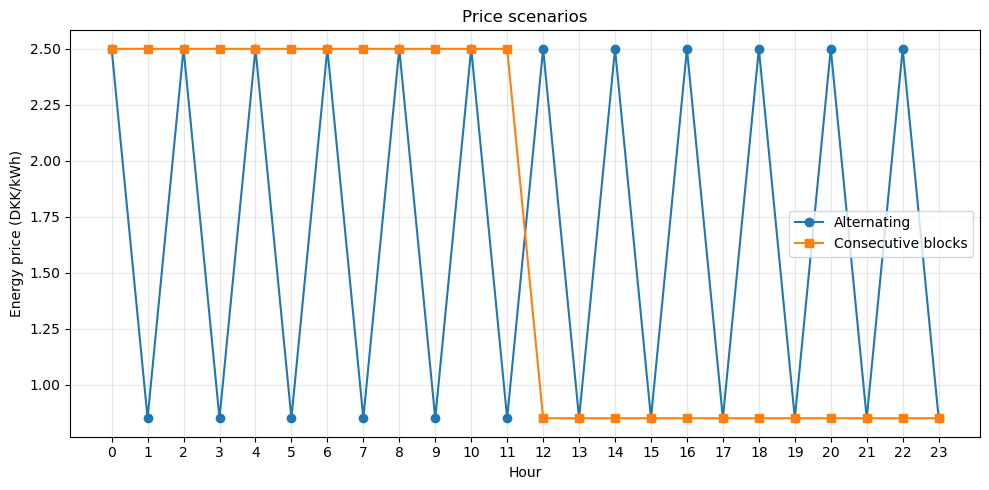

In [125]:
import matplotlib.pyplot as plt

hours = np.arange(24)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    hours,
    price_alternating,
    marker="o",
    label="Alternating"
)

ax.plot(
    hours,
    price_block,
    marker="s",
    label="Consecutive blocks"
)

ax.set_xlabel("Hour")
ax.set_ylabel("Energy price (DKK/kWh)")
ax.set_title("Price scenarios")
ax.set_xticks(hours)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [126]:
data_alt = copy.deepcopy(data)
data_block = copy.deepcopy(data)

data_alt.energy_price = price_alternating
data_block.energy_price = price_block

In [127]:
# -----------------------------
# Alternating price scenario
# -----------------------------
cL_base = 1.43
cQ_base = 1.0
gamma_base = 0.25

model_B_alt = LinearDisutilityModel(
    data_alt,
    cL=cL_base,
    name="Q2_linear_alt"
).build()

results_B_alt = model_B_alt.solve()


model_C_alt = QuadraticDisutilityModel(
    data_alt,
    cQ=cQ_base,
    name="Q2_quadratic_alt"
).build()

results_C_alt = model_C_alt.solve()


model_E_alt = TemporallyCoupledDisutilityModel(
    data_alt,
    cQ=cQ_base,
    gamma=gamma_base,
    name="Q2_temporal_alt"
).build()

results_E_alt = model_E_alt.solve()

In [128]:
# -----------------------------
# Consecutive-block price scenario
# -----------------------------

model_B_block = LinearDisutilityModel(
    data_block,
    cL=cL_base,
    name="Q2_linear_block"
).build()

results_B_block = model_B_block.solve()


model_C_block = QuadraticDisutilityModel(
    data_block,
    cQ=cQ_base,
    name="Q2_quadratic_block"
).build()

results_C_block = model_C_block.solve()


model_E_block = TemporallyCoupledDisutilityModel(
    data_block,
    cQ=cQ_base,
    gamma=gamma_base,
    name="Q2_temporal_block"
).build()

results_E_block = model_E_block.solve()

In [129]:
def calculate_metrics(results, data, model_type):
    load = results.hourly["load"]
    
    # Daily surplus
    surplus = -results.objective
    
    # Total absolute deviation
    abs_deviation = (
        load - data.reference_load
    ).abs().sum()
    
    return {
        "Surplus (DKK)": surplus,
        "Total absolute deviation (kWh)": abs_deviation,
        "Daily load (kWh)": load.sum()
    }

In [130]:
import pandas as pd

rows = []

cases = [
    ("Alternating", "Q2(b) Linear", results_B_alt, data_alt),
    ("Alternating", "Q2(c) Quadratic", results_C_alt, data_alt),
    ("Alternating", "Q2(e) Temporal", results_E_alt, data_alt),
    ("Block", "Q2(b) Linear", results_B_block, data_block),
    ("Block", "Q2(c) Quadratic", results_C_block, data_block),
    ("Block", "Q2(e) Temporal", results_E_block, data_block),
]

for scenario, model_name, result, scenario_data in cases:
    metrics = calculate_metrics(result, scenario_data, model_name)
    
    rows.append({
        "Price scenario": scenario,
        "Model": model_name,
        **metrics
    })

comparison_price = pd.DataFrame(rows)

display(comparison_price.round(4))

,Price scenario,Model,Surplus (DKK),Total absolute deviation (kWh),Daily load (kWh)
0,Alternating,Q2(b) Linear,35.0970,16.1400,16.2000
1,Alternating,Q2(c) Quadratic,37.1860,10.7850,21.5550
2,Alternating,Q2(e) Temporal,42.3377,6.0598,26.2802
3,Block,Q2(b) Linear,40.1856,15.0600,17.2800
4,Block,Q2(c) Quadratic,43.3780,11.6850,20.6550
5,Block,Q2(e) Temporal,50.0477,6.5096,25.8304


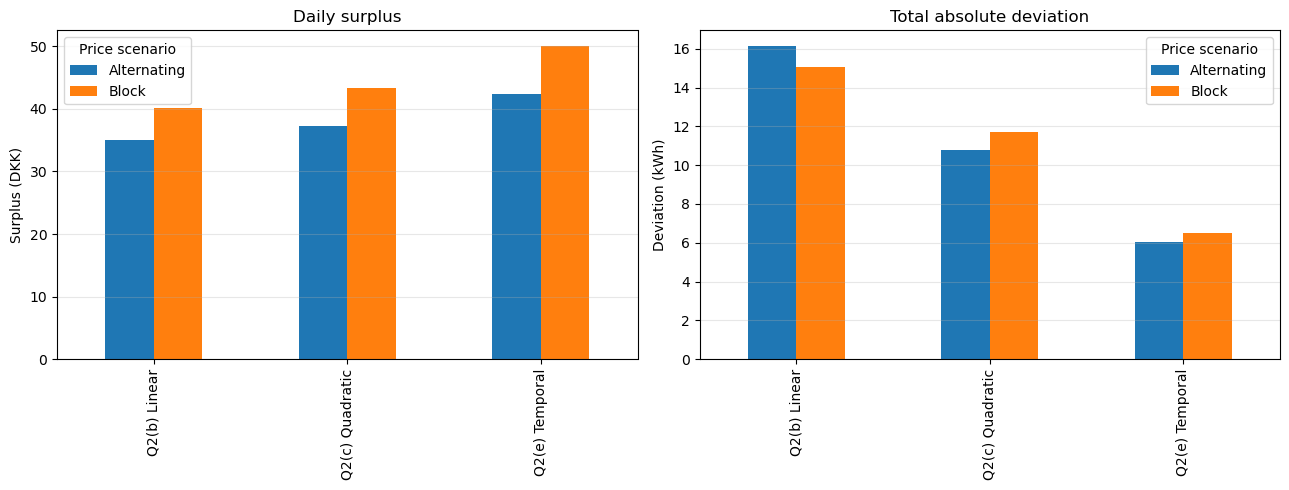

In [131]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# -----------------------------
# Daily surplus
# -----------------------------
pivot_surplus = comparison_price.pivot(
    index="Model",
    columns="Price scenario",
    values="Surplus (DKK)"
)

pivot_surplus.plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Daily surplus")
axes[0].set_ylabel("Surplus (DKK)")
axes[0].set_xlabel("")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(title="Price scenario")


# -----------------------------
# Total deviation
# -----------------------------
pivot_dev = comparison_price.pivot(
    index="Model",
    columns="Price scenario",
    values="Total absolute deviation (kWh)"
)

pivot_dev.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Total absolute deviation")
axes[1].set_ylabel("Deviation (kWh)")
axes[1].set_xlabel("")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(title="Price scenario")

plt.tight_layout()
plt.savefig(
    plots_folder_E / "Surplus and Abs deviation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()